# Studi Kasus 6 — *Attributing Direct Drivers to Deforestation Alerts with Satellite Imagery and AI*

**Pemateri:** Dr. Bart Slagter (Postdoctoral Researcher, Remote Sensing — Wageningen University & Research, Belanda)
**Video:** https://www.youtube.com/live/OFLzys5FYqg
**Seri:** Informatics Practitioner Lecture Series 2026 — Prodi Informatika Universitas Bengkulu

---

## Ringkasan materi pemateri

1. Hutan tropis menyimpan karbon, mengatur siklus air, menopang keanekaragaman hayati & mata pencaharian — tetapi
   hilang cepat karena perubahan penggunaan lahan dan ekstraksi sumber daya (kayu, tambang).
2. **Dua jenis citra Sentinel**: **optik (Sentinel-2)** kaya informasi vegetasi (termasuk inframerah) tetapi sering
   **tertutup awan** di tropis; **radar (Sentinel-1)** memancarkan pulsa dan mengukur *backscatter* sehingga
   **menembus awan**, walau lebih sulit diinterpretasi.
3. **Deforestation alerts** (mis. RADD, GLAD): gangguan hutan dideteksi ±mingguan pada piksel 10–30 m. Keterbatasannya:
   alert **tidak memberi tahu penyebabnya**.
4. Riset pemateri: **CNN** menerima tumpukan citra (2 band Sentinel-1 + 4 band Sentinel-2) setelah alert terdeteksi
   dan mengklasifikasikan **pemicu langsung** (*direct driver*): pertanian skala kecil/besar, jalan, tebang pilih,
   tambang, kebakaran, gangguan alami (banjir/angin), atau "tidak yakin". Model melihat **bentuk, ukuran, dan konteks
   sekitar** alert. Pertanian dipilah lagi berdasarkan **ukuran** dan **keberadaan api** (sensor *hotspot*).
5. Pembaruan **bulanan** memperlihatkan pola regional (Amerika Selatan: pertanian besar & kebakaran; Afrika Tengah:
   pertanian kecil & tebang pilih; Indonesia/Malaysia: campuran pertanian, tebang pilih, tambang), **urutan kejadian**
   (tambang → pertanian di sekitarnya; jalan → tebang pilih → kebakaran), dan **musiman** (Asia Tenggara kurang musiman).
6. **Evaluasi jujur**: akurasi keseluruhan tinggi karena didominasi kelas pertanian; **F1 yang menimbang setiap kelas
   setara** lebih rendah — kebakaran & banjir paling sering tertukar. Model diperbaiki dengan menambah contoh berlabel.
7. Keterbatasan: perbedaan cakupan sensor, latensi bulanan, pemicu awal ≠ penggunaan lahan akhir, kesalahan klasifikasi;
   **data lapangan tetap dibutuhkan**. Data paling bernilai bila **digabung dengan data lain** (batas konsesi,
   kawasan lindung, tenurial) di platform seperti Global Forest Watch / Global Nature Watch.
8. Tanya-jawab: selalu bandingkan **deep learning dengan metode konvensional** sebagai *benchmark* sebelum memakai
   model yang lebih mahal; Sentinel-1 berguna untuk banjir bila kanopi cukup terbuka.

## Latar belakang studi kasus

Bentang alam di sekitar **Taman Nasional Kerinci Seblat (TNKS)** di Provinsi Bengkulu menghadapi tekanan pembukaan
kebun, jalan, tebang liar, tambang emas rakyat, dan kebakaran. Balai taman nasional menerima ratusan *deforestation
alert* per bulan, tetapi **tidak tahu mana yang harus diprioritaskan untuk patroli**.

Kita membangun *pipeline* atribusi pemicu langsung mengikuti pendekatan pemateri:

```
alert (lokasi + area) ─► potongan citra S1 (VV,VH) + S2 (G,R,NIR,SWIR) ─► CNN ─► pemicu + keyakinan
                                  │                                              │
                        awan pada S2 (sering!)                pilah ukuran & hotspot api, gabung batas TNKS/konsesi
                                                                                 ▼
                                                    peta bulanan, musiman, daftar prioritas patroli
```

> ⚠️ Untuk dapat dijalankan di Colab tanpa akun Google Earth Engine, **citra Sentinel dibangkitkan secara sintetis**
> dengan karakter fisik yang disederhanakan (nilai *backscatter* dB dan reflektansi khas tiap tutupan, *speckle*, awan).
> Bagian akhir notebook menunjukkan cara mengganti data sintetis dengan citra Sentinel asli.

## Tujuan
1. Memahami perbedaan Sentinel-1 (radar) dan Sentinel-2 (optik), termasuk dampak awan.
2. Membangun *benchmark* konvensional (Random Forest + fitur buatan) dan **CNN** (PyTorch).
3. Mengevaluasi dengan jujur: akurasi keseluruhan vs **macro-F1**, *confusion matrix*, kelas "tidak yakin".
4. Uji ablasi S1 vs S2 vs S1+S2 pada kondisi berawan.
5. Pemantauan bulanan: pemilahan pertanian, deteksi api, musiman, dan integrasi dengan batas kawasan.

## 0. Persiapan

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from shapely.geometry import Point, box, Polygon
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
rng = np.random.default_rng(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| perangkat:", DEVICE,
      "(Colab: Runtime → Change runtime type → GPU untuk mempercepat)" if DEVICE == "cpu" else "")
sns.set_theme(style="white")

PyTorch 2.14.1+cpu | perangkat: cpu (Colab: Runtime → Change runtime type → GPU untuk mempercepat)


## 1. Membangkitkan potongan citra (*patch*) Sentinel sintetis

Setiap *patch* berukuran 32×32 piksel (10 m → 320×320 m) berpusat pada sebuah alert, berisi 7 kanal:

| Kanal | Sumber | Keterangan |
|---|---|---|
| VV, VH | Sentinel-1 (radar, dB) | hutan ±−7/−13 dB; lahan terbuka lebih rendah; **air sangat rendah** (±−20/−26 dB) |
| G, R, NIR, SWIR | Sentinel-2 (reflektansi) | hutan: NIR tinggi; tanah terbuka: R & SWIR tinggi; bekas terbakar: NIR rendah, SWIR tinggi; **awan: semua tinggi** |
| MASK | sistem alert | piksel yang terdeteksi berubah |

In [2]:
KELAS = ["pertanian", "jalan", "tebang_pilih", "tambang", "kebakaran", "gangguan_alami"]
PROPORSI = [0.52, 0.08, 0.10, 0.06, 0.13, 0.11]          # tidak seimbang, seperti data nyata
S = 32
TUTUPAN = {  #          VV     VH     G     R     NIR   SWIR
    "hutan":         (-7.0, -13.0, 0.05, 0.03, 0.30, 0.14),
    "tanah_terbuka": (-9.5, -17.0, 0.09, 0.12, 0.22, 0.28),
    "tanah_tambang": (-8.5, -16.0, 0.14, 0.18, 0.20, 0.33),
    "bekas_terbakar": (-10.5, -18.5, 0.04, 0.05, 0.11, 0.21),
    "air":           (-20.0, -26.0, 0.06, 0.05, 0.03, 0.02),
    "hutan_rusak":   (-8.0, -14.5, 0.06, 0.05, 0.24, 0.17),
}
yy, xx = np.mgrid[0:S, 0:S]

def blob(cx, cy, r, kasar=0.35):
    th = np.arctan2(yy - cy, xx - cx); d = np.hypot(yy - cy, xx - cx)
    rr = r * (1 + kasar * sum(rng.uniform(-1, 1) * np.sin(k * th + rng.uniform(0, 6.3)) for k in (2, 3, 5)))
    return d < rr

def garis(lebar=1.2, lengkung=0.0):
    a = rng.uniform(0, np.pi); c = rng.uniform(-6, 6)
    d = (xx - S / 2) * np.sin(a) - (yy - S / 2) * np.cos(a) - c - lengkung * np.sin((xx + yy) / 6)
    return np.abs(d) < lebar

def buat_patch(kelas, awan_p=0.5):
    peta = np.full((S, S), "hutan", dtype=object)
    mask = np.zeros((S, S), bool)
    sungai = garis(lebar=rng.uniform(1.2, 2.5), lengkung=2.5) if rng.random() < {"tambang": 0.75, "gangguan_alami": 0.9,
                                                                               "kebakaran": 0.45}.get(kelas, 0.12) else None
    cx, cy = rng.uniform(11, 21, 2)
    if kelas == "pertanian":
        r = rng.choice([rng.uniform(2.2, 4), rng.uniform(6, 11)], p=[0.6, 0.4])
        mask = blob(cx, cy, r, kasar=0.12) & (np.abs(xx - cx) < r * 0.95)            # petak cenderung bersudut
        peta[mask] = "tanah_terbuka"
    elif kelas == "jalan":
        mask = garis(lebar=rng.uniform(0.8, 1.5), lengkung=rng.uniform(0, 1.5)); peta[mask] = "tanah_terbuka"
    elif kelas == "tebang_pilih":
        jalur = garis(lebar=0.6, lengkung=1.0)
        for _ in range(rng.integers(5, 10)):
            pts = np.argwhere(jalur); py, px = pts[rng.integers(len(pts))] + rng.integers(-4, 5, 2)
            mask |= blob(px, py, rng.uniform(0.8, 1.6), kasar=0.2)
        if rng.random() < 0.5:                                                       # jalur sarad tidak selalu terlihat
            mask |= jalur & (rng.random((S, S)) < 0.5)
        peta[mask] = "hutan_rusak"
    elif kelas == "tambang":
        mask = blob(cx, cy, rng.uniform(4, 8), kasar=0.5); peta[mask] = "tanah_tambang"
        for _ in range(rng.integers(2, 5)):
            kolam = blob(cx + rng.uniform(-4, 4), cy + rng.uniform(-4, 4), rng.uniform(0.8, 1.8)) & mask
            peta[kolam] = "air"
    elif kelas == "kebakaran":
        mask = blob(cx, cy, rng.uniform(5, 13), kasar=0.55)
        peta[mask] = np.where(rng.random(mask.sum()) < rng.uniform(0.4, 0.9), "bekas_terbakar", "hutan_rusak")
    elif kelas == "gangguan_alami":
        if sungai is not None and rng.random() < 0.7:                                # banjir di dataran banjir
            dekat = np.zeros((S, S), bool)
            for dy in range(-4, 5):
                dekat |= np.roll(sungai, dy, axis=0)
            mask = dekat & blob(cx, cy, rng.uniform(6, 12), kasar=0.5)
            peta[mask] = rng.choice(["air", "bekas_terbakar", "hutan_rusak"], mask.sum(), p=[0.35, 0.35, 0.3])  # genangan + vegetasi mati
        else:                                                                        # angin ribut: robohan tersebar
            mask = blob(cx, cy, rng.uniform(5, 10), kasar=0.6) & (rng.random((S, S)) < 0.55)
            peta[mask] = "hutan_rusak"
    if sungai is not None:
        peta[sungai & ~mask] = "air"

    img = np.zeros((6, S, S), np.float32)
    for nama, nilai in TUTUPAN.items():
        sel = peta == nama
        # variasi antar-lokasi/musim: kelembapan tanah, umur tanaman, sudut matahari
        variasi = np.r_[rng.normal(0, 1.0, 2), rng.normal(1, 0.2, 4)]
        img[:2, sel] = (np.array(nilai[:2]) + variasi[:2])[:, None]
        img[2:, sel] = (np.array(nilai[2:]) * variasi[2:])[:, None]
    img[:2] += rng.normal(0, 1.8, (2, S, S))                                         # speckle radar
    img[2:] *= rng.normal(1, 0.12, (4, S, S)); img[2:] += rng.normal(0, 0.012, (4, S, S))
    berawan = rng.random() < awan_p
    if berawan:                                                                      # awan + bayangannya hanya mengganggu optik
        awan = blob(rng.uniform(0, S), rng.uniform(0, S), rng.uniform(8, 30), kasar=0.4)
        bayangan = np.roll(awan, (rng.integers(2, 6), rng.integers(2, 6)), axis=(0, 1)) & ~awan
        img[2:, bayangan] *= 0.35
        img[2:, awan] = rng.uniform(0.35, 0.6) + rng.normal(0, 0.03, (4, awan.sum()))
    # mask dari sistem alert tidak sempurna: sebagian piksel terlewat & ada alarm palsu
    mask_amatan = (mask & (rng.random((S, S)) > 0.3)) | (rng.random((S, S)) < 0.01)
    return np.concatenate([img, mask_amatan[None].astype(np.float32)]), berawan, int(mask.sum())

def buat_dataset(n, awan_p=0.5, salah_label=0.04):
    y = rng.choice(len(KELAS), n, p=PROPORSI)
    X, awan, luas = zip(*[buat_patch(KELAS[k], awan_p) for k in y])
    y_label = y.copy()                                                               # label interpretasi manusia
    salah = rng.random(n) < salah_label                                              # tidak 100% benar
    y_label[salah] = rng.integers(0, len(KELAS), salah.sum())
    return np.stack(X), y_label, np.array(awan), np.array(luas)

t0 = time.perf_counter()
X, y, awan, luas = buat_dataset(3000)
print(f"Dataset: {X.shape} dalam {time.perf_counter() - t0:.1f} s | berawan: {awan.mean():.0%}")
pd.Series(y).map(dict(enumerate(KELAS))).value_counts().rename("jumlah patch").to_frame().T

Dataset: (3000, 7, 32, 32) dalam 3.0 s | berawan: 49%


,pertanian,kebakaran,gangguan_alami,tebang_pilih,jalan,tambang
jumlah patch,1530,404,344,297,240,185


### 1.1 Melihat contoh: optik (RGB semu), NIR, radar VH, dan mask alert

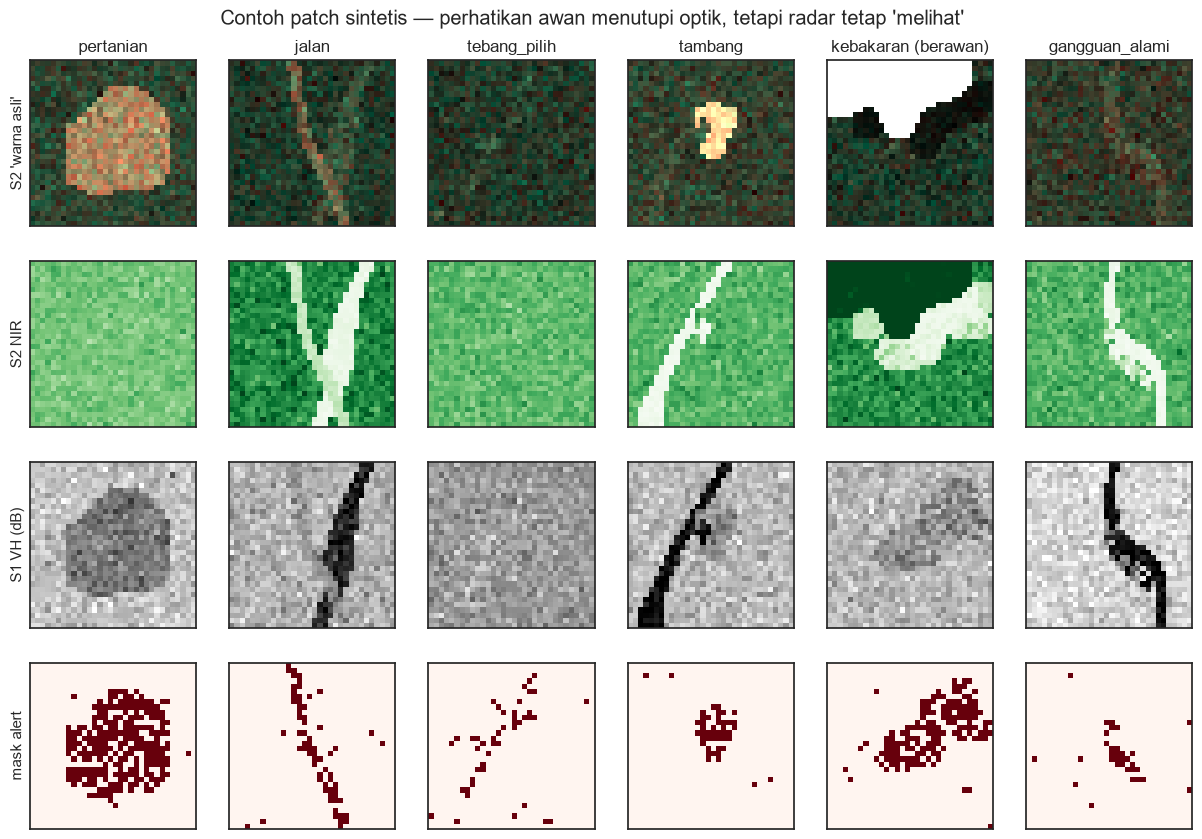

In [3]:
def rgb(p):
    return np.clip(np.stack([p[3], p[2], p[2] * 0.7], -1) / 0.2, 0, 1)    # R, G, (G) diperkuat untuk tampilan

fig, ax = plt.subplots(4, 6, figsize=(15, 10))
for j, k in enumerate(range(len(KELAS))):
    i = np.where((y == k) & (~awan))[0][0] if j != 4 else np.where((y == k) & awan)[0][0]
    ax[0, j].imshow(rgb(X[i])); ax[0, j].set_title(KELAS[k] + (" (berawan)" if awan[i] else ""))
    ax[1, j].imshow(X[i][4], cmap="Greens", vmin=0, vmax=0.5)
    ax[2, j].imshow(X[i][1], cmap="gray", vmin=-28, vmax=-8)
    ax[3, j].imshow(X[i][6], cmap="Reds")
for a, lbl in zip(ax[:, 0], ["S2 'warna asli'", "S2 NIR", "S1 VH (dB)", "mask alert"]):
    a.set_ylabel(lbl, fontsize=11)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.suptitle("Contoh patch sintetis — perhatikan awan menutupi optik, tetapi radar tetap 'melihat'", y=0.93); plt.show()

## 2. Pembagian data & *benchmark* konvensional (Random Forest)

Sesuai saran pemateri, kita **mulai dari metode konvensional** dengan fitur buatan tangan: statistik tiap band di
dalam & di luar mask (konteks), luas & kerampingan mask, fraksi air radar, dan NDVI.

In [4]:
idx = np.arange(len(y))
i_latih, i_uji = train_test_split(idx, test_size=0.25, stratify=y, random_state=SEED)
i_latih, i_val = train_test_split(i_latih, test_size=0.15, stratify=y[i_latih], random_state=SEED)
print(f"latih={len(i_latih)}, validasi={len(i_val)}, uji={len(i_uji)}")

def fitur_buatan(p):
    m = p[6] > 0.5; f = []
    for b in range(6):
        dalam = p[b][m] if m.any() else p[b].ravel()
        f += [dalam.mean(), dalam.std(), p[b][~m].mean()]
    luas = m.sum()
    if luas > 2:
        cy, cx = np.nonzero(m); ev = np.linalg.eigvalsh(np.cov(np.vstack([cx, cy])) + 1e-6 * np.eye(2))
        ramping = ev[1] / ev[0]
    else:
        ramping = 1
    ndvi = (p[4] - p[3]) / (p[4] + p[3] + 1e-6)
    f += [luas, ramping, (p[0] < -16).mean(), ndvi[m].mean() if m.any() else 0, (p[2:6].mean(0) > 0.3).mean()]
    return f

F_all = np.array([fitur_buatan(p) for p in X])
rf = RandomForestClassifier(400, class_weight="balanced", random_state=SEED, n_jobs=-1).fit(F_all[i_latih], y[i_latih])
pred_rf = rf.predict(F_all[i_uji])
print(f"Random Forest — akurasi {accuracy_score(y[i_uji], pred_rf):.3f} | macro-F1 {f1_score(y[i_uji], pred_rf, average='macro'):.3f}")

latih=1912, validasi=338, uji=750


Random Forest — akurasi 0.912 | macro-F1 0.886


## 3. *Convolutional Neural Network* (CNN)

CNN membaca **seluruh tumpukan citra** (7 kanal) sehingga dapat mempelajari bentuk, tekstur, dan konteks sekitar
alert secara otomatis. Kita pakai augmentasi rotasi/cermin (citra satelit tidak punya arah "atas") dan *loss*
berbobot kelas agar kelas minoritas (tambang, jalan) tidak diabaikan.

In [5]:
mean = X[i_latih].mean(axis=(0, 2, 3), keepdims=True); std = X[i_latih].std(axis=(0, 2, 3), keepdims=True) + 1e-6
mean[:, 6], std[:, 6] = 0, 1                                                       # mask tidak dinormalisasi
Xn = ((X - mean) / std).astype(np.float32)

class CNNPemicu(nn.Module):
    def __init__(self, c_in=7, n_kelas=len(KELAS)):
        super().__init__()
        def blok(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(),
                                             nn.Conv2d(o, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU())
        self.fitur = nn.Sequential(blok(c_in, 32), nn.MaxPool2d(2), blok(32, 64), nn.MaxPool2d(2), blok(64, 128))
        self.kepala = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(128, n_kelas))
    def forward(self, x): return self.kepala(self.fitur(x))

def augmentasi(xb):
    k = int(torch.randint(0, 4, (1,)))
    xb = torch.rot90(xb, k, dims=(2, 3))
    return torch.flip(xb, dims=(3,)) if torch.rand(1) < 0.5 else xb

def latih_cnn(kanal, epoch=18, verbose=True):
    torch.manual_seed(SEED)
    model = CNNPemicu(c_in=len(kanal)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, total_steps=epoch * int(np.ceil(len(i_latih) / 64)))
    bobot = torch.tensor(len(i_latih) / (len(KELAS) * np.bincount(y[i_latih])), dtype=torch.float32, device=DEVICE)
    Xt = torch.tensor(Xn[:, kanal]); yt = torch.tensor(y)
    riwayat = []
    for ep in range(epoch):
        model.train(); perm = np.random.default_rng(ep).permutation(i_latih)
        for b in range(0, len(perm), 64):
            j = perm[b:b + 64]
            xb, yb = augmentasi(Xt[j]).to(DEVICE), yt[j].to(DEVICE)
            loss = F.cross_entropy(model(xb), yb, weight=bobot)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        p_val = prediksi(model, kanal, i_val).argmax(1)
        riwayat.append((ep + 1, loss.item(), accuracy_score(y[i_val], p_val), f1_score(y[i_val], p_val, average="macro")))
        if verbose and (ep + 1) % 3 == 0:
            print(f"epoch {ep + 1:2d} | loss {loss.item():.3f} | val acc {riwayat[-1][2]:.3f} | val macro-F1 {riwayat[-1][3]:.3f}")
    return model, pd.DataFrame(riwayat, columns=["epoch", "loss", "val_acc", "val_macroF1"])

@torch.no_grad()
def prediksi(model, kanal, indeks, Xsumber=None):
    model.eval(); Xs = Xn if Xsumber is None else Xsumber
    out = [F.softmax(model(torch.tensor(Xs[indeks[b:b + 256]][:, kanal]).to(DEVICE)), 1).cpu().numpy()
           for b in range(0, len(indeks), 256)]
    return np.concatenate(out)

SEMUA = [0, 1, 2, 3, 4, 5, 6]
t0 = time.perf_counter()
cnn, riwayat = latih_cnn(SEMUA)
print(f"Waktu latih: {time.perf_counter() - t0:.0f} s")

epoch  3 | loss 1.030 | val acc 0.358 | val macro-F1 0.366


epoch  6 | loss 0.650 | val acc 0.509 | val macro-F1 0.457


epoch  9 | loss 0.583 | val acc 0.737 | val macro-F1 0.749


epoch 12 | loss 0.175 | val acc 0.861 | val macro-F1 0.852


epoch 15 | loss 0.237 | val acc 0.947 | val macro-F1 0.925


epoch 18 | loss 0.252 | val acc 0.953 | val macro-F1 0.934
Waktu latih: 57 s


## 4. Evaluasi yang jujur

Pemateri menekankan: **akurasi keseluruhan** didominasi kelas mayoritas (pertanian), sehingga perlu metrik yang
**menimbang setiap kelas setara** — di scikit-learn disebut **macro-F1** (`average="macro"`).

,Akurasi keseluruhan,Macro-F1 (tiap kelas setara),Weighted-F1 (sesuai jumlah)
Random Forest (fitur buatan),0.912,0.886,0.912
CNN (S1+S2+mask),0.953,0.933,0.953


                precision    recall  f1-score   support

     pertanian      0.974     0.979     0.977       383
         jalan      0.950     0.950     0.950        60
  tebang_pilih      0.863     0.932     0.896        74
       tambang      0.927     0.826     0.874        46
     kebakaran      0.940     0.931     0.935       101
gangguan_alami      0.976     0.953     0.965        86

      accuracy                          0.953       750
     macro avg      0.938     0.929     0.933       750
  weighted avg      0.954     0.953     0.953       750



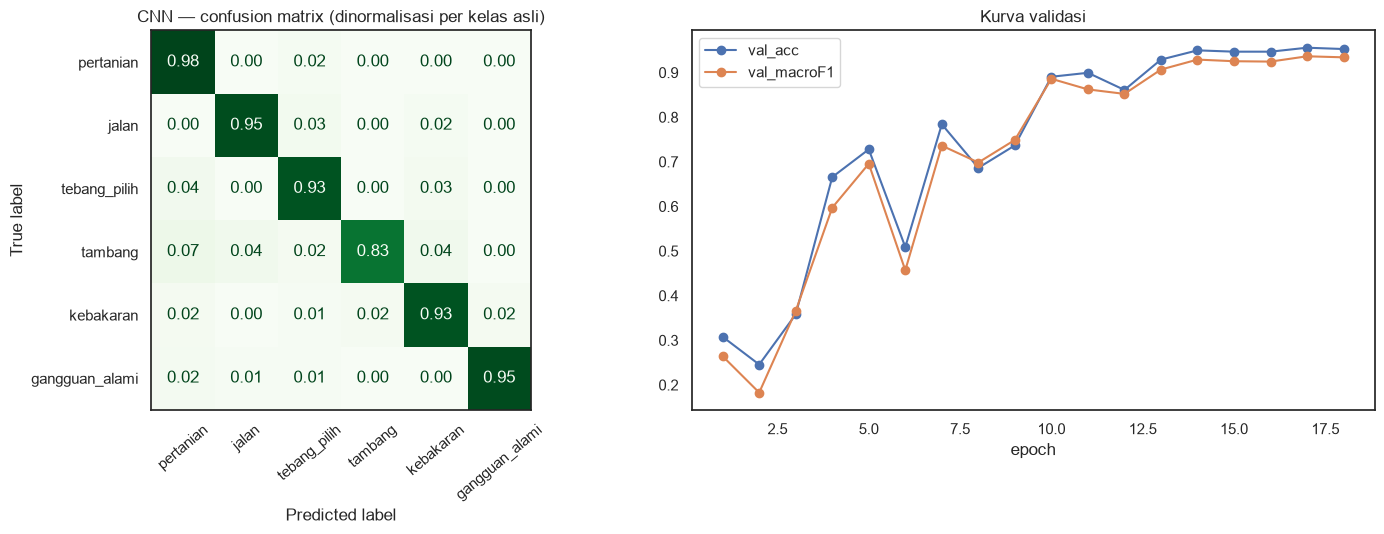

Pasangan kelas yang paling sering tertukar (jumlah kesalahan dua arah):
  pertanian       ↔ tebang_pilih   : 9
  pertanian       ↔ tambang        : 4
  tambang         ↔ kebakaran      : 4
Catatan: ±4% label sengaja dibuat salah (meniru kesalahan interpretasi manusia), sehingga skor 100% mustahil.


In [6]:
prob_uji = prediksi(cnn, SEMUA, i_uji); pred_cnn = prob_uji.argmax(1)
ringkas = pd.DataFrame({
    "Akurasi keseluruhan": [accuracy_score(y[i_uji], pred_rf), accuracy_score(y[i_uji], pred_cnn)],
    "Macro-F1 (tiap kelas setara)": [f1_score(y[i_uji], pred_rf, average="macro"), f1_score(y[i_uji], pred_cnn, average="macro")],
    "Weighted-F1 (sesuai jumlah)": [f1_score(y[i_uji], pred_rf, average="weighted"), f1_score(y[i_uji], pred_cnn, average="weighted")],
}, index=["Random Forest (fitur buatan)", "CNN (S1+S2+mask)"]).round(3)
display(ringkas)
print(classification_report(y[i_uji], pred_cnn, target_names=KELAS, digits=3))

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
ConfusionMatrixDisplay(confusion_matrix(y[i_uji], pred_cnn, normalize="true"), display_labels=KELAS).plot(
    ax=ax[0], cmap="Greens", values_format=".2f", colorbar=False, xticks_rotation=40)
ax[0].set_title("CNN — confusion matrix (dinormalisasi per kelas asli)")
riwayat.plot(x="epoch", y=["val_acc", "val_macroF1"], ax=ax[1], marker="o"); ax[1].set_title("Kurva validasi")
plt.tight_layout(); plt.show()

cm = confusion_matrix(y[i_uji], pred_cnn)
tertukar = [(KELAS[a], KELAS[b], cm[a, b] + cm[b, a]) for a in range(len(KELAS)) for b in range(a + 1, len(KELAS))]
print("Pasangan kelas yang paling sering tertukar (jumlah kesalahan dua arah):")
for a, b, n in sorted(tertukar, key=lambda t: -t[2])[:3]:
    print(f"  {a:15s} ↔ {b:15s}: {n}")
print("Catatan: ±4% label sengaja dibuat salah (meniru kesalahan interpretasi manusia), sehingga skor 100% mustahil.")

### 4.1 Kelas "tidak yakin"
Seperti sistem pemateri, prediksi dengan keyakinan rendah diberi label **tidak yakin** alih-alih dipaksa ke satu
kelas. Ada *trade-off*: makin tinggi ambang, makin akurat prediksi yang tersisa, tetapi makin banyak alert tanpa label.

In [7]:
yakin = prob_uji.max(1)
baris = []
for amb in [0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    m = yakin >= amb
    baris.append({"ambang keyakinan": amb, "cakupan (% alert berlabel)": 100 * m.mean(),
                  "akurasi pada yang berlabel": accuracy_score(y[i_uji][m], pred_cnn[m]),
                  "macro-F1 pada yang berlabel": f1_score(y[i_uji][m], pred_cnn[m], average="macro")})
pd.DataFrame(baris).round(3)

,ambang keyakinan,cakupan (% alert berlabel),akurasi pada yang berlabel,macro-F1 pada yang berlabel
0,0.0,100.000,0.953,0.933
1,0.5,99.200,0.958,0.938
2,0.6,97.200,0.964,0.946
3,0.7,93.867,0.969,0.954
4,0.8,82.400,0.971,0.960
5,0.9,58.667,0.966,0.961


## 5. Uji ablasi: apa gunanya radar saat berawan?
Kita latih tiga CNN dengan kanal berbeda dan menilai kinerjanya **terpisah untuk patch cerah dan berawan**.
(Model ablasi dilatih 12 epoch agar cepat; model utama S1+S2 memakai 18 epoch.)

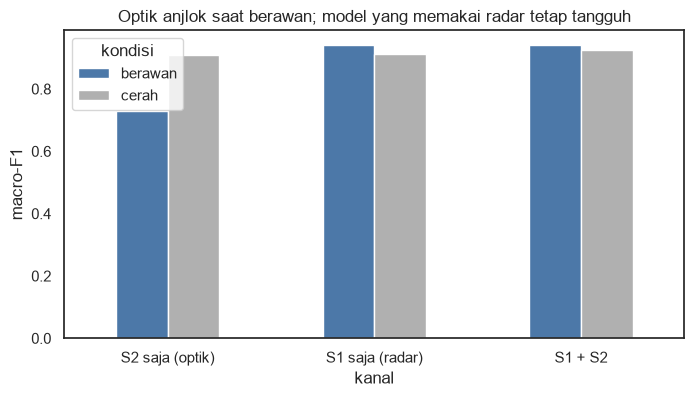

kondisi,berawan,cerah
kanal,,
S2 saja (optik),0.730,0.908
S1 saja (radar),0.941,0.911
S1 + S2,0.940,0.924


In [8]:
konfig = {"S2 saja (optik)": [2, 3, 4, 5, 6], "S1 saja (radar)": [0, 1, 6], "S1 + S2": SEMUA}
abl = []
for nama, kanal in konfig.items():
    m = cnn if kanal == SEMUA else latih_cnn(kanal, epoch=12, verbose=False)[0]
    p = prediksi(m, kanal, i_uji).argmax(1)
    for kondisi, sel in [("cerah", ~awan[i_uji]), ("berawan", awan[i_uji])]:
        abl.append({"kanal": nama, "kondisi": kondisi, "macro-F1": f1_score(y[i_uji][sel], p[sel], average="macro")})
abl = pd.DataFrame(abl).pivot(index="kanal", columns="kondisi", values="macro-F1").loc[list(konfig)]
ax = abl.plot(kind="bar", figsize=(8, 4), color=["#4C78A8", "#B0B0B0"], rot=0); ax.set_ylabel("macro-F1")
ax.set_title("Optik anjlok saat berawan; model yang memakai radar tetap tangguh"); plt.show()
abl.round(3)

## 6. Pemantauan bulanan bentang alam sekitar TNKS (36 bulan)

Kita simulasikan alert selama Okt 2023 – Sep 2026 di bentang alam ±40×30 km yang memuat **kawasan taman nasional**,
**konsesi perkebunan (HGU)**, dan **wilayah izin tambang**. Pemicu sebenarnya mengikuti pola musiman (kebakaran &
pembukaan lahan memuncak di musim kemarau Jun–Sep) dan pola ruang (tambang dekat sungai, pertanian dekat jalan/desa).
Setiap alert diberi patch citra lalu **diklasifikasikan oleh CNN** — persis alur operasional bulanan.

In [9]:
CRS = "EPSG:32748"
x0, y0 = 760_000, 9_600_000
tn = gpd.GeoDataFrame({"nama": ["Taman Nasional (sintetis)"]}, geometry=[Polygon(
    [(x0, y0 + 14_000), (x0 + 22_000, y0 + 30_000), (x0, y0 + 30_000)])], crs=CRS)
hgu = gpd.GeoDataFrame({"nama": ["HGU sawit A", "HGU sawit B"]},
                       geometry=[box(x0 + 24_000, y0, x0 + 36_000, y0 + 9_000), box(x0 + 30_000, y0 + 12_000, x0 + 40_000, y0 + 20_000)], crs=CRS)
iup = gpd.GeoDataFrame({"nama": ["IUP tambang"]}, geometry=[box(x0 + 8_000, y0 + 4_000, x0 + 16_000, y0 + 10_000)], crs=CRS)

bulan = pd.period_range("2023-10", "2026-09", freq="M")
pola_bulan = {  # bobot musiman per bulan kalender (1..12)
    "pertanian":      [0.7, 0.7, 0.8, 0.9, 1.0, 1.0, 1.1, 1.3, 1.5, 1.6, 1.5, 1.2],
    "kebakaran":      [0.2, 0.2, 0.3, 0.3, 0.4, 0.6, 1.0, 1.8, 2.6, 2.8, 2.0, 0.6],
    "jalan":          [1.0] * 12, "tebang_pilih": [0.9, 0.9, 1.0, 1.0, 1.0, 1.1, 1.1, 1.1, 1.0, 1.0, 1.0, 0.9],
    "tambang":        [1.0] * 12, "gangguan_alami": [1.8, 1.6, 1.4, 1.0, 0.8, 0.6, 0.5, 0.4, 0.5, 0.8, 1.3, 1.8],
}
rata_per_bulan = dict(zip(KELAS, [28, 4, 6, 4, 6, 4]))
lok = {"pertanian": (x0 + 26_000, y0 + 10_000, 9_000), "jalan": (x0 + 18_000, y0 + 14_000, 9_000),
       "tebang_pilih": (x0 + 9_000, y0 + 20_000, 6_000), "tambang": (x0 + 12_000, y0 + 8_000, 4_000),
       "kebakaran": (x0 + 30_000, y0 + 15_000, 8_000), "gangguan_alami": (x0 + 18_000, y0 + 4_000, 8_000)}
alert = []
for b in bulan:
    for k in KELAS:
        n = rng.poisson(rata_per_bulan[k] * pola_bulan[k][b.month - 1] * (1 + 0.15 * (b.year - 2023)))
        cx, cy, sd = lok[k]
        for _ in range(n):
            alert.append({"bulan": b, "pemicu_asli": k, "x": rng.normal(cx, sd), "y": rng.normal(cy, sd)})
alert = pd.DataFrame(alert)
alert = alert[(alert.x.between(x0, x0 + 40_000)) & (alert.y.between(y0, y0 + 30_000))].reset_index(drop=True)

# patch citra tiap alert → CNN (awan lebih sering di musim hujan)
awan_bulan = alert.bulan.dt.month.map(lambda m: 0.75 if m in (10, 11, 12, 1, 2, 3, 4) else 0.35).values
Xa = np.stack([buat_patch(k, p)[0] for k, p in zip(alert.pemicu_asli, awan_bulan)])
luas_px = Xa[:, 6].sum((1, 2))
Xa_n = ((Xa - mean) / std).astype(np.float32)
pa = prediksi(cnn, SEMUA, np.arange(len(alert)), Xsumber=Xa_n)
alert["pemicu_prediksi"] = np.array(KELAS)[pa.argmax(1)]
alert["keyakinan"] = pa.max(1)
alert.loc[alert.keyakinan < 0.6, "pemicu_prediksi"] = "tidak_yakin"
alert["luas_ha"] = luas_px * 0.01                                                # 1 piksel = 10×10 m = 0,01 ha
print(f"{len(alert)} alert dalam 36 bulan | akurasi CNN operasional (tanpa 'tidak yakin'): "
      f"{(alert.pemicu_prediksi == alert.pemicu_asli)[alert.pemicu_prediksi != 'tidak_yakin'].mean():.3f}")

2055 alert dalam 36 bulan | akurasi CNN operasional (tanpa 'tidak yakin'): 0.990


### 6.1 Pemilahan pertanian (ukuran) & keterkaitan api (*hotspot*)
Seperti pemateri: alert pertanian dipilah menjadi **skala kecil (< 1 ha)** dan **skala besar (≥ 1 ha)**, lalu dicek
apakah bertepatan dengan **titik panas** (mis. NASA FIRMS / VIIRS) — menandakan pembukaan lahan dengan cara membakar.

In [10]:
p_api = np.select([alert.pemicu_asli == "kebakaran", (alert.pemicu_asli == "pertanian") & (alert.luas_ha >= 1),
                   alert.pemicu_asli == "pertanian"], [0.9, 0.35, 0.12], 0.03)
alert["hotspot"] = rng.random(len(alert)) < p_api                                # data sensor api (sintetis)
pert = alert.pemicu_prediksi == "pertanian"
alert.loc[pert, "pemicu_rinci"] = np.where(alert.loc[pert, "luas_ha"] >= 1, "pertanian skala besar", "pertanian skala kecil")
alert.loc[pert & alert.hotspot, "pemicu_rinci"] += " + api"
alert["pemicu_rinci"] = alert.pemicu_rinci.fillna(alert.pemicu_prediksi)
alert.pemicu_rinci.value_counts().to_frame("jumlah alert")

,jumlah alert
pemicu_rinci,
pertanian skala kecil,587
tebang_pilih,249
pertanian skala besar,239
kebakaran,232
tambang,160
jalan,159
pertanian skala besar + api,142
gangguan_alami,123
tidak_yakin,90


### 6.2 Tren bulanan & indeks musiman
Indeks musiman $= 1 - H/\ln 12$, dengan $H$ entropi sebaran alert per bulan kalender: 0 = merata sepanjang tahun,
mendekati 1 = terkonsentrasi di bulan tertentu.

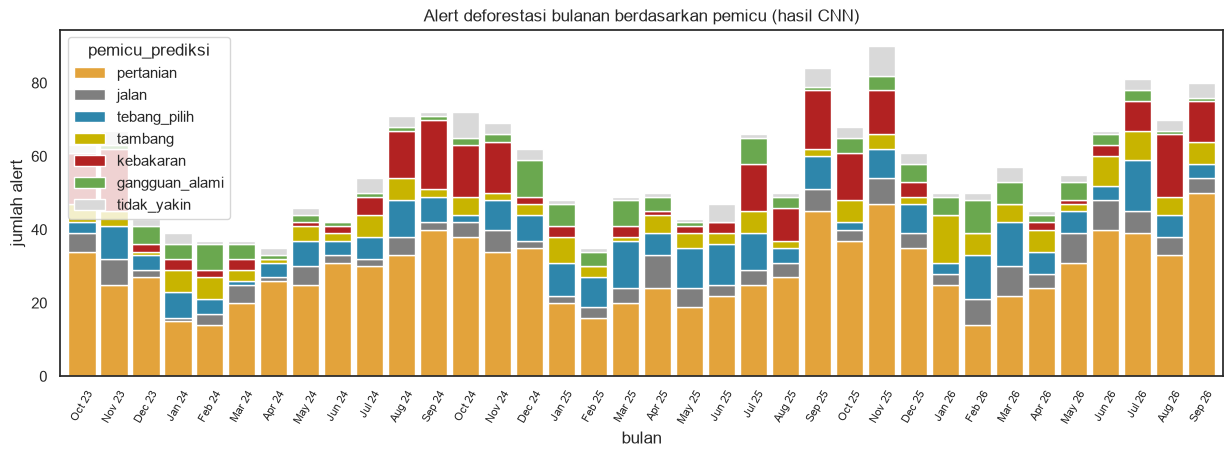

,indeks musiman
kebakaran,0.166
gangguan_alami,0.066
tambang,0.028
jalan,0.017
tebang_pilih,0.017
pertanian,0.016


In [11]:
tab = alert.groupby([alert.bulan.dt.to_timestamp(), "pemicu_prediksi"]).size().unstack(fill_value=0)
warna = {"pertanian": "#E3A33B", "jalan": "#7F7F7F", "tebang_pilih": "#2E86AB", "tambang": "#C8B400",
         "kebakaran": "#B22222", "gangguan_alami": "#6AA84F", "tidak_yakin": "#D9D9D9"}
ax = tab[[k for k in warna if k in tab]].plot(kind="bar", stacked=True, figsize=(15, 4.5), width=0.85,
                                              color=[warna[k] for k in warna if k in tab])
ax.set_xticklabels([d.strftime("%b %y") for d in tab.index], rotation=60, fontsize=8)
ax.set_ylabel("jumlah alert"); ax.set_title("Alert deforestasi bulanan berdasarkan pemicu (hasil CNN)"); plt.show()

def indeks_musiman(s):
    p = s.groupby(s.index.month).sum(); p = p / p.sum()
    return 1 - (-(p[p > 0] * np.log(p[p > 0])).sum()) / np.log(12)
musiman = pd.Series({k: indeks_musiman(tab[k]) for k in KELAS if k in tab}).sort_values(ascending=False)
musiman.round(3).to_frame("indeks musiman")

### 6.3 Menggabungkan dengan batas kawasan → daftar prioritas patroli
Pemateri menyebut alert paling bernilai bila digabung dengan data lain (konsesi, kawasan lindung). Aturan prioritas:
* **Prioritas 1** — di dalam taman nasional & pemicu tambang / tebang pilih / jalan (ilegal hampir pasti);
* **Prioritas 2** — di dalam taman nasional & pemicu pertanian/kebakaran, atau tambang di luar wilayah IUP;
* lainnya dipantau (mis. pembukaan di dalam HGU yang berizin).

prioritas        P1  P2  pantau
pemicu_prediksi                
gangguan_alami    0   0     123
jalan            15   0     144
kebakaran         0   1     231
pertanian         0  14    1028
tambang           0  92      68
tebang_pilih     92   0     157
tidak_yakin       0   0      90


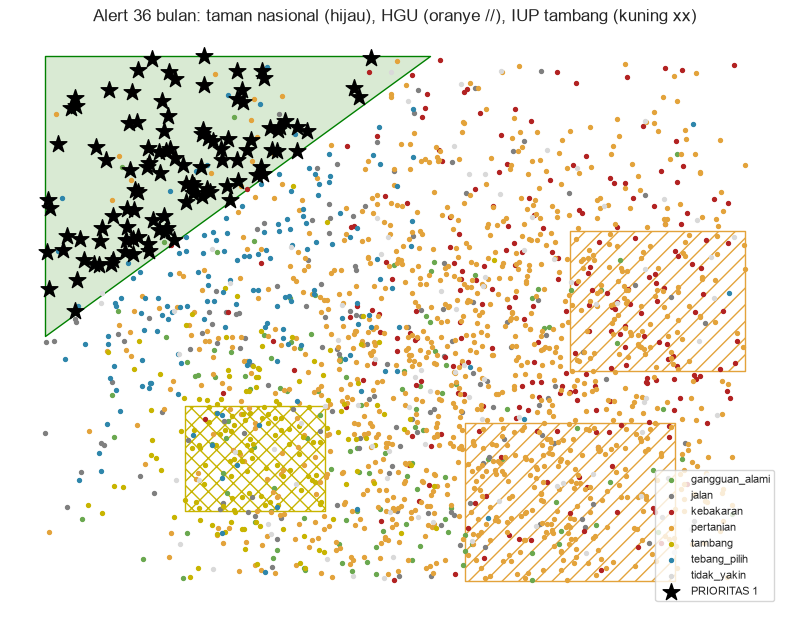

,bulan,pemicu_prediksi,keyakinan,luas_ha,x,y
2030,2026-09,tebang_pilih,0.99,0.36,763458.0,9624017.0
1947,2026-08,tebang_pilih,0.99,0.43,778607.0,9629866.0
1946,2026-08,tebang_pilih,0.99,0.32,765272.0,9626204.0
1871,2026-07,jalan,0.99,0.66,768061.0,9622679.0
1884,2026-07,tebang_pilih,0.98,0.33,760262.0,9621328.0
1882,2026-07,tebang_pilih,0.98,0.23,761459.0,9627036.0
1874,2026-07,tebang_pilih,0.94,0.46,769232.0,9622380.0
1799,2026-06,jalan,0.99,0.70,770967.0,9624062.0
1809,2026-06,tebang_pilih,0.98,0.34,777940.0,9627622.0
1806,2026-06,tebang_pilih,0.98,0.48,764814.0,9626156.0


In [12]:
ga = gpd.GeoDataFrame(alert, geometry=gpd.points_from_xy(alert.x, alert.y), crs=CRS)
ga["di_TN"] = ga.within(tn.union_all()); ga["di_HGU"] = ga.within(hgu.union_all()); ga["di_IUP"] = ga.within(iup.union_all())
ilegal_tn = ga.pemicu_prediksi.isin(["tambang", "tebang_pilih", "jalan"])
ga["prioritas"] = np.select(
    [ga.di_TN & ilegal_tn & (ga.keyakinan >= 0.8),
     (ga.di_TN & ga.pemicu_prediksi.isin(["pertanian", "kebakaran"])) | ((ga.pemicu_prediksi == "tambang") & ~ga.di_IUP)],
    ["P1", "P2"], "pantau")
print(pd.crosstab(ga.pemicu_prediksi, ga.prioritas))

fig, ax = plt.subplots(figsize=(10, 7.5))
tn.plot(ax=ax, color="#d9ead3", edgecolor="green"); hgu.plot(ax=ax, color="none", edgecolor="#E3A33B", hatch="//")
iup.plot(ax=ax, color="none", edgecolor="#C8B400", hatch="xx")
for k, d in ga.groupby("pemicu_prediksi"):
    d.plot(ax=ax, markersize=8, color=warna[k], label=k)
ga[ga.prioritas == "P1"].plot(ax=ax, marker="*", markersize=160, color="black", label="PRIORITAS 1")
ax.legend(loc="lower right", fontsize=8); ax.set_axis_off()
ax.set_title("Alert 36 bulan: taman nasional (hijau), HGU (oranye //), IUP tambang (kuning xx)"); plt.show()

ga[ga.prioritas == "P1"].sort_values(["bulan", "keyakinan"], ascending=[False, False])[
    ["bulan", "pemicu_prediksi", "keyakinan", "luas_ha", "x", "y"]].head(10).round({"keyakinan": 2, "luas_ha": 2, "x": 0, "y": 0})

### 6.4 Urutan kejadian (*sequence*)
Pemateri menunjukkan jalan → tebang pilih → kebakaran di Bolivia, dan tambang → pertanian di Kongo. Kita cek: untuk
setiap alert tebang pilih, berapa persen yang didahului alert **jalan** dalam radius 2 km pada 12 bulan sebelumnya?

In [13]:
def didahului(asal, tujuan, radius=2000, jendela=12):
    a = ga[ga.pemicu_prediksi == asal]; b = ga[ga.pemicu_prediksi == tujuan]
    hasil = []
    for _, r in b.iterrows():
        cand = a[(a.bulan < r.bulan) & (a.bulan >= r.bulan - jendela)]
        hasil.append((cand.distance(r.geometry) <= radius).any() if len(cand) else False)
    return np.mean(hasil) if hasil else np.nan
print(f"Tebang pilih yang didahului jalan (≤2 km, ≤12 bln): {didahului('jalan', 'tebang_pilih'):.0%}")
print(f"Pertanian yang didahului tambang  (≤2 km, ≤12 bln): {didahului('tambang', 'pertanian'):.0%}")

Tebang pilih yang didahului jalan (≤2 km, ≤12 bln): 39%


Pertanian yang didahului tambang  (≤2 km, ≤12 bln): 18%


## 7. Mengganti data sintetis dengan citra Sentinel asli (langkah lanjut)

```python
!pip install earthengine-api geemap
import ee; ee.Authenticate(); ee.Initialize(project="PROYEK-GCP-ANDA")
aoi = ee.Geometry.Rectangle([101.9, -3.4, 102.3, -3.0])            # sekitar TNKS, Bengkulu
radd = ee.ImageCollection("projects/radar-wur/raddalert/v1").filterMetadata("layer", "contains", "alert")
s1 = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(aoi).filterDate("2026-08-01", "2026-09-01")
      .filter(ee.Filter.eq("instrumentMode", "IW")).select(["VV", "VH"]).median())
s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(aoi).filterDate("2026-08-01", "2026-09-01")
      .select(["B3", "B4", "B8", "B11"]).median())
# lalu ekspor patch 32×32 di sekitar setiap piksel alert (mis. geemap.ee_to_numpy / Export.image.toDrive),
# beri label dari interpretasi visual / data lapangan, dan latih ulang CNN di atas.
```

Label lapangan dari **polhut / Balai TN** sangat berharga: pemateri menegaskan model membaik ketika diberi lebih banyak
contoh berlabel, terutama untuk kelas yang sering tertukar (kebakaran vs banjir).

## 8. Kesimpulan

* **Benchmark dulu**: Random Forest dengan fitur buatan sudah cukup baik, tetapi CNN yang membaca bentuk & konteks
  memberi macro-F1 lebih tinggi — sesuai saran pemateri untuk selalu membandingkan dengan metode konvensional.
* **Metrik yang jujur**: akurasi keseluruhan tampak lebih tinggi daripada macro-F1 karena didominasi kelas
  pertanian. Lihat daftar pasangan kelas yang paling sering tertukar di bagian 4 — pada data nyata pemateri,
  kebakaran ↔ banjir/gangguan alami adalah yang tersulit, sehingga model dilatih ulang dengan contoh tambahan.
* **Radar penting di tropis**: saat berawan, model optik saja anjlok, sedangkan model yang memakai radar (S1 saja
  maupun S1+S2) tetap tangguh; saat cerah, gabungan S1+S2 memberi hasil terbaik.
* **Ambang keyakinan** memberi pilihan antara cakupan dan ketepatan label ("tidak yakin").
* Nilai operasional muncul setelah hasil **digabung dengan batas kawasan**: daftar prioritas patroli, pola musiman
  kebakaran & pembukaan lahan, serta urutan jalan → tebang pilih.

**Keterbatasan:** citra sintetis jauh lebih sederhana daripada citra nyata; label pemicu langsung belum tentu sama
dengan penggunaan lahan akhirnya; latensi bulanan; dan **verifikasi lapangan tetap diperlukan** sebelum penegakan hukum.